# Which GPU work did PyTorch launch?

`capture` profiles one warmed-up training step and returns `prof.events()`.
`rows` holds every event once, with `launcher_id` pointing at the event that
launched it (a CPU op's `cpu_parent`, or a kernel's CUDA launch call), so
`aten::mm -> cudaLaunchKernel -> kernel` is a chain of `launcher_id` links.

Module hooks record `forward::<module_fqn>` scopes, and autograd node hooks restore
the same path as `backward::<module_fqn>` during backward. A kernel belongs to its
nearest module scope; with none it is `<unattributed>`. `aggregate_kernels` does the
attribution and raises if a kernel is owned by a module but never reaches the root scope.

1. Setup and capture
2. Every kernel with its module
3. Time per module
4. Timeline
5. FLOPs check
6. Appendix: what each id is, and one kernel's launch chain

In [1]:
import pickle

import pandas as pd
import torch
from profile_events import (
    aggregate_kernels,
    display_timeline,
    events_to_rows,
    link_events,
    module_scopes,
    transformer_matmul_comparison,
)

from models.transformer import Transformer

model = Transformer(
    vocab_size=100,
    d_model=32,
    d_ff=128,
    sequence_length=250,
    num_layers=2,
    num_heads=2,
    rope_theta=10000,
    device="cuda",  # has to agree with app.GPU; the preflight checks it
    dtype="torch.float32",  # strings parsed in the worker container
)
tokens = torch.randint(
    0, 100, (8, 250),
    generator=torch.Generator().manual_seed(0),
)

### What `capture` does

`capture` runs on a GPU worker and profiles one training step.

1. Build the model and make random tokens.
2. Run a few warmup steps, unprofiled.
3. Run one step under the profiler, with the CUDA allocator recording its history. Each phase of the step is wrapped in `record_function`, so it shows up by name: `train::zero_grad`, `train::forward`, `train::loss`, `train::backward`, `train::optimizer_step`.
4. Return the profiler's events and the allocator's `memory_snapshot`.

**`record_function(name)`** adds a `user_annotation` event with that name. It is a label we add, not an operation PyTorch ran. Anything that starts and ends inside its time span becomes its child, so parent and child are decided by timestamps.

**`module_scopes(model)`** does the same per module: `forward::<module>` around each module's forward call, and `backward::<module>` around the backward work it owns. Later, a kernel is assigned to the module whose scope contains its launch.

A typical start of the events, in order, with start and end times in microseconds (illustrative values; the ids are from a real capture). `device_type` says where an event executed, CPU or GPU. Each indented row is a child of the row above it that is one level less indented. Annotations are ours, the rest is PyTorch:

```
                                          device_type     activity_type                               correlation_id        linked_correlation_id  start    end
train::zero_grad                          DeviceType.CPU  user_annotation                      1 (frontend, PyTorch)                            0      0     40
  Optimizer.zero_grad#AdamW.zero_grad     DeviceType.CPU  user_annotation (PyTorch's own)      2 (frontend, PyTorch)                            0      5     35
train::forward                            DeviceType.CPU  user_annotation                      3 (frontend, PyTorch)                            0     40   4200
  forward::model                          DeviceType.CPU  user_annotation                      4 (frontend, PyTorch)                            0     45   4190
    forward::model.embedding              DeviceType.CPU  user_annotation                      5 (frontend, PyTorch)                            0     50    300
      aten::index                         DeviceType.CPU  cpu_op                               6 (frontend, PyTorch)                            0     60    290
        cudaLaunchKernel                  DeviceType.CPU  cuda_runtime                           11 (backend, CUPTI)        6 (frontend, PyTorch)    100    120
          vectorized_gather_kernel        DeviceType.CUDA kernel (on the GPU)                    11 (backend, CUPTI)        6 (frontend, PyTorch)    130    142
```

**Linking.** Parent and child among CPU events come from the timestamps, as above. A GPU event has no CPU parent in the trace, so `link_events` finds its launcher with correlation ids.

**CUDA** is NVIDIA's platform for running programs on its GPUs. It has a CPU side and a GPU side:

- On the CPU, the CUDA runtime library (`cuda_runtime` events, e.g. `cudaLaunchKernel`, `cudaMemcpyAsync`) and the lower-level driver it calls into (`cuda_driver`). These are ordinary CPU function calls that queue work for the GPU and return immediately.
- On the GPU, the work that was queued: `kernel`, `gpu_memcpy`, `gpu_memset`.

The `correlation_id` column holds ids from two separate namespaces, and the same number can appear in both. The boundary is who recorded the event, not CPU versus GPU:

- **Frontend:** events PyTorch's own profiler records for the operations your Python code calls: `cpu_op` and `user_annotation`. PyTorch numbers them with its own counter (1 to 6 above).
- **Backend:** every event of the CUDA layer, recorded by CUPTI, NVIDIA's profiling library (the CUDA Profiling Tools Interface). That is both the CPU-side CUDA calls (`cuda_runtime`, `cuda_driver`) and the GPU work they launch (`kernel`, `gpu_memcpy`, `gpu_memset`). CUPTI numbers them with its own counter (11 above), and a kernel gets the same id as the call that launched it.

So `device_type` is not the namespace boundary. `cudaLaunchKernel` has `DeviceType.CPU` because it executes on the CPU, yet its `correlation_id` is a backend id. `DeviceType.CUDA` marks only the GPU-side events, so it is not a name for the whole backend namespace. The namespace follows `activity_type`.

`linked_correlation_id` crosses between them. On a launch call or GPU event it holds the frontend `correlation_id` of the op that issued the launch (6, `aten::index`).

`link_events` keeps one lookup per namespace, so an id is only ever compared with ids of its own kind:

1. A kernel's backend `correlation_id` is looked up among the launch calls, so it is matched to the `cuda_runtime` call that launched it (11).
2. The launch call's `linked_correlation_id` is looked up among the frontend ids, so the call is matched to the op that issued it (6).

Each match sets `launcher_id` to the matched event's row. Following `launcher_id` from the kernel gives `kernel -> cudaLaunchKernel -> aten::index -> forward::model.embedding -> ...`, which is how a kernel finds its module scope. If a match is missing or ambiguous, `launcher_id` stays empty and the kernel is unattributed. See "What each id is" in the appendix.

In [2]:
import modal

import main

app = modal.App("profile-events")
# The worker image, so its torch is the uv.lock version that unpickles the events locally.
# The container imports profile_events for module_scopes.
image = main.worker_image.add_local_python_source("profile_events")


@app.function(image=image, gpu="T4", timeout=300)
def capture(declaration, tokens, warmup_steps=5) -> tuple:
    """Warm up full training steps, then profile one step on the same model.

    Returns (profiler events, CUDA allocator snapshot) for that step.

    Warmup includes forward, loss, backward and optimizer.step so CUDA libraries
    and optimizer state are initialized. Warmup events are not recorded.
    """
    import torch
    from torch import nn
    from torch.profiler import ProfilerActivity, profile, record_function

    torch.manual_seed(0)
    model = declaration.build()
    tokens = tokens.to("cuda")
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    # Next-token prediction: each position predicts the following input token.
    targets = tokens[:, 1:].reshape(-1)

    def train_step():
        with record_function("train::zero_grad"):
            optimizer.zero_grad(set_to_none=True)
        with record_function("train::forward"):
            logits = model(tokens)
        with record_function("train::loss"):
            loss = nn.functional.cross_entropy(
                logits[:, :-1, :].reshape(-1, logits.shape[-1]), targets
            )
        with record_function("train::backward"):
            loss.backward()
        with record_function("train::optimizer_step"):
            optimizer.step()

    # Complete warmup before profiling: no queued warmup work enters the trace.
    for _ in range(warmup_steps):
        train_step()
    torch.cuda.synchronize()

    torch.cuda.memory._record_memory_history(max_entries=100_000)
    with profile(
        activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
        record_shapes=False,
        with_stack=False,
        with_flops=True,
        profile_memory=False
    ) as prof, module_scopes(model):
        train_step()
        # Kernels run asynchronously. Wait for them inside the profiler so every launched
        # activity has finished, and been recorded, before collection stops.
        torch.cuda.synchronize()
    # A plain dict of segments, blocks and allocator trace entries: it pickles without a file.
    memory_snapshot = torch.cuda.memory._snapshot()
    torch.cuda.memory._record_memory_history(enabled=None)
    # The FunctionEvents themselves: they pickle with their cpu_parent/cpu_children references.
    return list(prof.events()), memory_snapshot

In [3]:
# enable_output streams image builds and the container's logs into this cell.
with app.run():
    function_events, memory_snapshot = capture.remote(model, tokens, warmup_steps=5)
print(f"{len(function_events)} events")
rows = events_to_rows(function_events)

4677 events


In [20]:
print(pd.DataFrame(memory_snapshot['external_annotations']).to_string())

      stage                                      name  device           time_us
0     START                          train::zero_grad       0  1791839242005437
1     START       Optimizer.zero_grad#AdamW.zero_grad       0  1791839242005855
2       END       Optimizer.zero_grad#AdamW.zero_grad       0  1791839242006478
3       END                          train::zero_grad       0  1791839242006524
4     START                            train::forward       0  1791839242006551
5     START                            forward::model       0  1791839242006625
6     START                  forward::model.embedding       0  1791839242006713
7       END                  forward::model.embedding       0  1791839242013825
8     START                  forward::model.tblocks.0       0  1791839242013926
9     START            forward::model.tblocks.0.norm1       0  1791839242014406
10      END            forward::model.tblocks.0.norm1       0  1791839242016513
11    START        forward::model.tblock

## Every kernel and its module

In [5]:
# Raises if a module-owned kernel never reaches the root scope.
groups, kernels, unattributed_kernels, flop_sources = aggregate_kernels(rows, depth=3)
print(f"{len(kernels)} kernels, {len(unattributed_kernels)} unattributed")
assert len(unattributed_kernels) < len(kernels), "No kernel has a module: check module_scopes and root"
# Unattributed kernels show module_fqn "<unattributed>".
kernel_table = kernels[["name", "phase", "module_fqn", "owner_fqn", "duration_us", "gpu_start_us", "device_memory_usage", "cpu_memory_usage"]].sort_values('device_memory_usage')
display(kernel_table)

362 kernels, 57 unattributed


,name,phase,module_fqn,owner_fqn,duration_us,gpu_start_us,device_memory_usage,cpu_memory_usage
index,,,,,,,,
11,"void at::native::vectorized_gather_kernel<16, ...",forward,model.embedding,model.embedding,11.872,8866.955,0,0
3940,"void at::native::elementwise_kernel<128, 2, at...",backward,model.tblocks.0,model.tblocks.0.attention.rope,5.024,162521.794,0,0
3917,void at::native::(anonymous namespace)::CatArr...,backward,model.tblocks.0,model.tblocks.0.attention.rope,11.553,161617.912,0,0
3903,"void at::native::elementwise_kernel<128, 2, at...",backward,model.tblocks.0,model.tblocks.0.attention.rope,6.048,161076.082,0,0
3890,"void at::native::elementwise_kernel<128, 2, at...",backward,model.tblocks.0,model.tblocks.0.attention.rope,5.888,160515.244,0,0
...,...,...,...,...,...,...,...,...
994,void at::native::vectorized_elementwise_kernel...,forward,model.tblocks.1,model.tblocks.1,5.408,43944.915,0,0
987,volta_sgemm_32x32_sliced1x4_tn,forward,model.tblocks.1,model.tblocks.1.ffn,26.177,43038.217,0,0
965,void at::native::vectorized_elementwise_kernel...,forward,model.tblocks.1,model.tblocks.1.ffn,9.120,42701.574,0,0


## Time per module

In [6]:
# gpu_time_us sums kernel durations; gpu_span_us also includes gaps between launches.
display(groups[["kernel_count", "gpu_time_us", "gpu_span_us", "estimated_flops"]])

kernel_count  gpu_time_us  gpu_span_us  \
phase          module_fqn                                                
forward        model.embedding             1       11.872       11.872   
               model.linear                1       22.304       22.304   
               model.norm                  6       37.152      854.378   
               model.tblocks.0            55      647.912    17177.376   
               model.tblocks.1            55      654.661    16783.643   
loss           <unattributed>              3       44.128      335.204   
backward       <unattributed>             46      223.332   131234.748   
               model.embedding             7       60.769      728.009   
               model.linear                3       50.112      145.633   
               model.norm                 15      104.961     2900.544   
               model.tblocks.0            81     1245.165    59654.908   
               model.tblocks.1            81     1242.157    56807.579   
optimizer_step <unattributed>              8       57.697     1146.797   

                                estimated_flops  
phase          module_fqn                        
forward        model.embedding              0.0  
               model.linear          12800000.0  
               model.norm               66000.0  
               model.tblocks.0      130388000.0  
               model.tblocks.1      130388000.0  
loss           <unattributed>               0.0  
backward       <unattributed>          256000.0  
               model.embedding           2000.0  
               model.linear          25600000.0  
               model.norm              324000.0  
               model.tblocks.0      262000000.0  
               model.tblocks.1      262000000.0  
optimizer_step <unattributed>               0.0

## Timeline

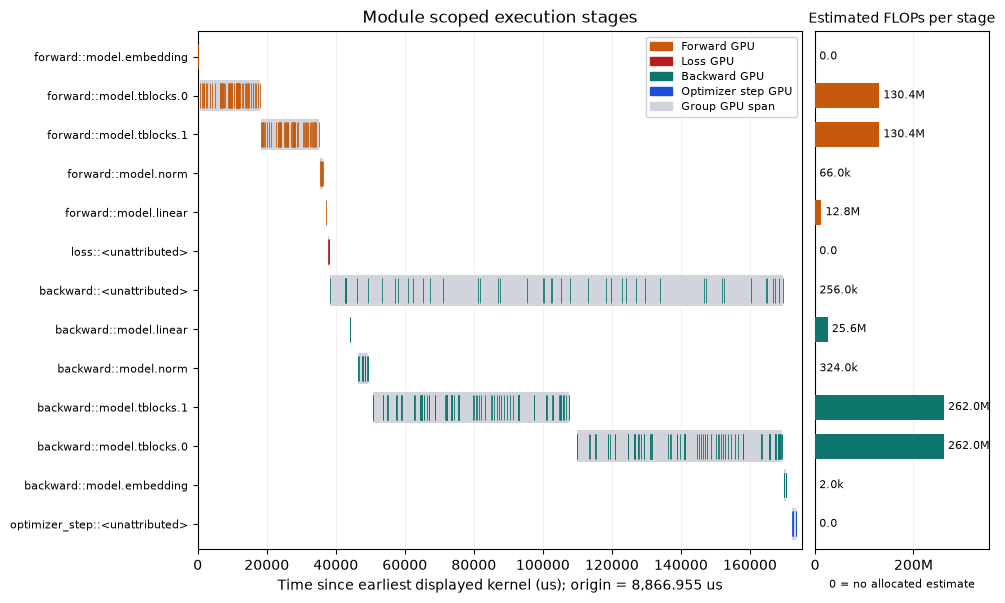

In [7]:
display_timeline(groups, kernels, figsize=(10, 6), show_flops=True)

## FLOPs check

In [8]:
from dataclasses import replace

batch, sequence = tokens.shape
parameter_count = sum(parameter.numel() for parameter in replace(model, device="cpu").build().parameters())
print(f"Parameters: {parameter_count:,}; tokens: {batch * sequence:,}")
print(f"6 × all parameters × tokens: {6 * parameter_count * batch * sequence / 1e6:,.3f} MFLOPs")
print("Comparison below in MFLOPs; matrix estimates exclude normalization, activations, loss and optimizer work.")
phase_comparison, stage_comparison = transformer_matmul_comparison(model, tokens, rows)
display(phase_comparison.div(1e6).round(6))
display(stage_comparison.div(1e6).round(6))
# 0 reported non-matrix FLOPs is not proof of zero work: many operations have
# no estimate. Backward = 2*forward applies to this unfrozen dense model's
# matmuls; freezing weights, detaching tensors or changing the model alters it.

Parameters: 39,328; tokens: 2,000
6 × all parameters × tokens: 471.936 MFLOPs
Comparison below in MFLOPs; matrix estimates exclude normalization, activations, loss and optimizer work.


,analytical_matmul_flops,profiler_matmul_flops,profiler_total_flops,profiler_other_flops,matmul_difference
phase,,,,,
forward,271.872,271.872,273.642,1.770,0.0
backward,543.744,543.744,550.182,6.438,0.0
forward + backward,815.616,815.616,823.824,8.208,0.0


analytical_matmul_flops  \
phase    module_fqn                                           
backward model.linear                                25.600   
         model.tblocks.0.attention                  160.768   
         model.tblocks.0.ffn                         98.304   
         model.tblocks.1.attention                  160.768   
         model.tblocks.1.ffn                         98.304   
forward  model.linear                                12.800   
         model.tblocks.0.attention                   80.384   
         model.tblocks.0.ffn                         49.152   
         model.tblocks.1.attention                   80.384   
         model.tblocks.1.ffn                         49.152   

                                    profiler_matmul_flops  difference  
phase    module_fqn                                                    
backward model.linear                              25.600         0.0  
         model.tblocks.0.attention                160.768         0.0  
         model.tblocks.0.ffn                       98.304         0.0  
         model.tblocks.1.attention                160.768         0.0  
         model.tblocks.1.ffn                       98.304         0.0  
forward  model.linear                              12.800         0.0  
         model.tblocks.0.attention                 80.384         0.0  
         model.tblocks.0.ffn                       49.152         0.0  
         model.tblocks.1.attention                 80.384         0.0  
         model.tblocks.1.ffn                       49.152         0.0

## Appendix

## What each id is

`correlation_id` is `FunctionEvent.id`, which `_parse_kineto_results` fills with
`kineto_event.correlation_id()`. What it counts depends on the kind of row:

| Row (`activity_type`) | `correlation_id` | `linked_correlation_id` | `external_id` |
| --- | --- | --- | --- |
| Frontend: op or `record_function` scope (`cpu_op`, `user_annotation`) | PyTorch's own counter | 0 | `correlation_id` |
| Launch call on the CPU (`cuda_runtime`, `cuda_driver`) | CUPTI's counter | the op's `correlation_id` | `linked_correlation_id` |
| GPU work (`kernel`, `gpu_memcpy`, `gpu_memset`) | CUPTI's counter, equal to its launch call's | the op's `correlation_id` | `linked_correlation_id` |
| GPU span of a scope (`gpu_user_annotation`) | its scope's `correlation_id` | 0 | `correlation_id` |
| Profiler overhead (`overhead`) | reuses the `correlation_id` of the op it interrupted | 0 | 0 |

Two counters share the `correlation_id` column, so every lookup by it is restricted to one kind of row:
in one capture `Optimizer.step`'s GPU span and an unrelated launch call were both 1912.
`external_id` holds no value of its own: `KinetoEvent::externalId()` returns
`linked_correlation_id` when there is one, else `correlation_id`.

In [9]:
# One kernel's launch chain, CPU root -> CUDA launch -> kernel.
kernel_id = kernels.index[0]  # Change this to any kernel row ID.
chain, current = [], kernel_id
while pd.notna(current):
    chain.append(current)
    current = rows.loc[current, "launcher_id"]
print("Module:", kernels.loc[kernel_id, "module_fqn"])
display(rows.loc[chain[::-1]])

Module: model.embedding


,correlation_id,node_id,name,overload_name,trace_name,time_range,thread,fwd_thread,count,input_shapes,...,external_id,linked_correlation_id,event_metadata,structured_input_shapes,structured_input_strides,input_dtypes,python_id,python_parent_id,python_module_id,launcher_id
index,,,,,,,,,,,,,,,,,,,,,
2,3,-1,train::forward,,train::forward,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,3,0,None,[],[],[],-1,-1,-1,<NA>
3,4,-1,forward::model,,forward::model,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,4,0,None,[],[],[],-1,-1,-1,2
4,5,-1,forward::model.embedding,,forward::model.embedding,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,5,0,None,[],[],[],-1,-1,-1,3
5,6,-1,aten::index,,aten::index,<torch.autograd.profiler_util.Interval object ...,1,0,1,"[[100, 32], []]",...,6,0,None,"[[100, 32], []]","[[32, 1], []]","[float, ]",-1,-1,-1,4
10,18,-1,cudaLaunchKernel,,cudaLaunchKernel,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,6,6,None,[],[],[],-1,-1,-1,5
11,18,-1,"void at::native::vectorized_gather_kernel<16, ...",,"void at::native::vectorized_gather_kernel<16, ...",<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,6,6,None,[],[],[],-1,-1,-1,10
